# Detecting Heart Abnormality using ECG with CART
#### Machine Learning Mini-Project  


## 1. Import libraries and load the dataset

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)


In [2]:
DATA_FILE = "data/arrhythmia.data"
if DATA_FILE is None:
    raise FileNotFoundError(
        "Could not find the dataset."
    )

raw = pd.read_csv(DATA_FILE, header=None, na_values="?")
print("Dataset shape (rows, columns):", raw.shape)
display(raw.head())

Dataset shape (rows, columns): (452, 280)


,0,1,2,3,4,5,6,7,8,9,...,270,271,272,273,274,275,276,277,278,279
0,75,0,190,80,91,193,371,174,121,-16,...,0.0,9.0,-0.9,0.0,0.0,0.9,2.9,23.3,49.4,8
1,56,1,165,64,81,174,401,149,39,25,...,0.0,8.5,0.0,0.0,0.0,0.2,2.1,20.4,38.8,6
2,54,0,172,95,138,163,386,185,102,96,...,0.0,9.5,-2.4,0.0,0.0,0.3,3.4,12.3,49.0,10
3,55,0,175,94,100,202,380,179,143,28,...,0.0,12.2,-2.2,0.0,0.0,0.4,2.6,34.6,61.6,1
4,75,0,190,80,88,181,360,177,103,-16,...,0.0,13.1,-3.6,0.0,0.0,-0.1,3.9,25.4,62.8,7


## 2. Clean and observe the data

In [18]:
X = raw.iloc[:, :-1].apply(pd.to_numeric, errors="coerce")
y_multiclass = pd.to_numeric(raw.iloc[:, -1], errors="coerce").astype(int)

#  Attribute 14 (index 13) is removed because there are many missing values
missing_attribute_14 = int(X.iloc[:, 13].isna().sum())
X = X.drop(columns=[13])

y_binary = y_multiclass.copy()
y_binary[y_binary != 1] = 0

print(f"Rows: {len(raw)}")
print(f"Input features after removing attribute 14: {X.shape[1]}")
print(f"Missing values in original attribute 14: {missing_attribute_14} / {len(raw)}")

print("Observed original class labels:", sorted(y_multiclass.unique()))

print("\nOriginal multiclass distribution:")
display(y_multiclass.value_counts().sort_index().rename("records").to_frame())

Rows: 452
Input features after removing attribute 14: 278
Missing values in original attribute 14: 376 / 452
Observed original class labels: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 14, 15, 16]

Original multiclass distribution:


,records
279,
1,245
2,44
3,15
4,15
5,13
6,25
7,3
8,2
9,9


## 3. Train-test split

In [ ]:
# 70-30 split
Xm_train, Xm_test, ym_train, ym_test = train_test_split(
    X, y_multiclass, test_size=0.30, random_state=42, stratify=y_multiclass
)
print("Training rows:", len(Xm_train))
print("Testing rows:", len(Xm_test))


Training rows: 316
Testing rows: 136


## 4. CART model Comparison

In [ ]:
# Baseline multiclass CART model
baseline_multiclass_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("cart", DecisionTreeClassifier(criterion="gini", random_state=42))
])
baseline_multiclass_model.fit(Xm_train, ym_train)
ym_baseline_pred = baseline_multiclass_model.predict(Xm_test)

baseline_multiclass_accuracy = accuracy_score(ym_test, ym_baseline_pred)
baseline_multiclass_balanced_accuracy = balanced_accuracy_score(ym_test, ym_baseline_pred)
baseline_multiclass_macro_f1 = f1_score(ym_test, ym_baseline_pred, average="macro", zero_division=0)

print(f"Accuracy:          {baseline_multiclass_accuracy:.4f} ({baseline_multiclass_accuracy*100:.2f}%)")
print(f"Balanced accuracy: {baseline_multiclass_balanced_accuracy:.4f} ({baseline_multiclass_balanced_accuracy*100:.2f}%)")
print(f"Macro F1-score:    {baseline_multiclass_macro_f1:.4f}")
print("\nClassification report:")
print(classification_report(ym_test, ym_baseline_pred, zero_division=0))

Accuracy:          0.6912 (69.12%)
Balanced accuracy: 0.3698 (36.98%)
Macro F1-score:    0.3657

Classification report:
              precision    recall  f1-score   support

           1       0.81      0.85      0.83        74
           2       0.67      0.46      0.55        13
           3       0.67      0.50      0.57         4
           4       0.50      0.50      0.50         4
           5       0.00      0.00      0.00         4
           6       0.54      0.88      0.67         8
           7       0.00      0.00      0.00         1
           8       0.00      0.00      0.00         1
           9       0.67      0.67      0.67         3
          10       0.67      0.67      0.67        15
          14       0.00      0.00      0.00         1
          15       0.00      0.00      0.00         1
          16       0.33      0.29      0.31         7

    accuracy                           0.69       136
   macro avg       0.37      0.37      0.37       136
weighted avg  

In [ ]:
# Tuned multiclass CART model

from sklearn.model_selection import GridSearchCV, StratifiedKFold

tuned_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("cart", DecisionTreeClassifier(criterion="gini", random_state=42))
])
param_grid = {
    "cart__max_depth": [None, 5, 7, 10, 12, 15],
    "cart__min_samples_leaf": [1, 2, 3, 5],
    "cart__class_weight": [None, "balanced"],
    "cart__ccp_alpha": [0.0, 0.001, 0.005, 0.01],
}
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
tuned_multiclass_search = GridSearchCV(
    tuned_pipeline,
    param_grid=param_grid,
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1,
    refit=True,
    error_score="raise"
)
tuned_multiclass_search.fit(Xm_train, ym_train)
tuned_multiclass_model = tuned_multiclass_search.best_estimator_
ym_tuned_pred = tuned_multiclass_model.predict(Xm_test)


tuned_multiclass_accuracy = accuracy_score(ym_test, ym_tuned_pred)
tuned_multiclass_balanced_accuracy = balanced_accuracy_score(ym_test, ym_tuned_pred)
tuned_multiclass_macro_f1 = f1_score(ym_test, ym_tuned_pred, average="macro", zero_division=0)

print(f"Accuracy:          {tuned_multiclass_accuracy:.4f} ({tuned_multiclass_accuracy*100:.2f}%)")
print(f"Balanced accuracy: {tuned_multiclass_balanced_accuracy:.4f} ({tuned_multiclass_balanced_accuracy*100:.2f}%)")
print(f"Macro F1-score:    {tuned_multiclass_macro_f1:.4f}")
print("\nClassification report:")
print(classification_report(ym_test, ym_tuned_pred, zero_division=0))


c:\Users\Nihira\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\model_selection\_split.py:776: UserWarning: The least populated class in y has only 1 members, which is less than n_splits=3.
  warnings.warn(


Accuracy:          0.5588 (55.88%)
Balanced accuracy: 0.3996 (39.96%)
Macro F1-score:    0.3666

Classification report:
              precision    recall  f1-score   support

           1       0.82      0.62      0.71        74
           2       0.40      0.62      0.48        13
           3       0.57      1.00      0.73         4
           4       0.50      0.25      0.33         4
           5       0.67      0.50      0.57         4
           6       0.64      0.88      0.74         8
           7       0.00      0.00      0.00         1
           8       0.00      0.00      0.00         1
           9       0.60      1.00      0.75         3
          10       0.71      0.33      0.45        15
          14       0.00      0.00      0.00         1
          15       0.00      0.00      0.00         1
          16       0.00      0.00      0.00         7

    accuracy                           0.56       136
   macro avg       0.38      0.40      0.37       136
weighted avg  

In [10]:
def multiclass_metrics(y_true, y_pred):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Balanced accuracy": balanced_accuracy_score(y_true, y_pred),
        "Macro F1": f1_score(y_true, y_pred, average="macro", zero_division=0),
    }
    
baseline_metrics = multiclass_metrics(ym_test, ym_baseline_pred)
tuned_metrics = multiclass_metrics(ym_test, ym_tuned_pred)
multiclass_comparison = pd.DataFrame({
    "Metric": list(baseline_metrics.keys()),
    "Baseline multiclass CART": list(baseline_metrics.values()),
    "Tuned multiclass CART": list(tuned_metrics.values()),
})
display(multiclass_comparison.round(4))

,Metric,Baseline multiclass CART,Tuned multiclass CART
0,Accuracy,0.6912,0.5588
1,Balanced accuracy,0.3698,0.3996
2,Macro F1,0.3657,0.3666


Since Baseline multiclass CART model has a higher accuracy, that will be used further.

## 5. Confusion matrix

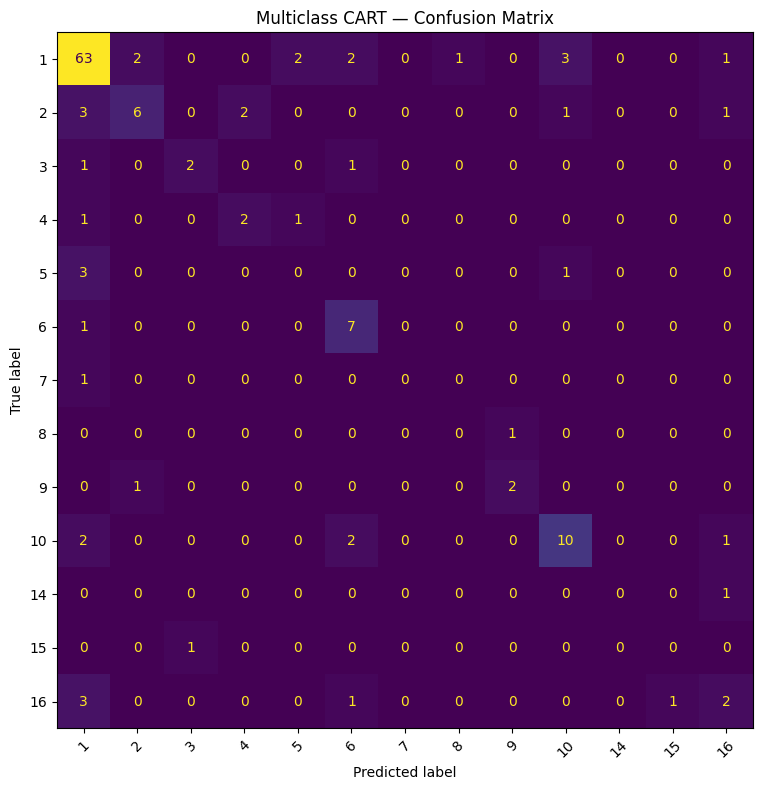

In [13]:
multiclass_labels = sorted(y_multiclass.unique())
cm_multi = confusion_matrix(ym_test, ym_baseline_pred, labels=multiclass_labels)
fig, ax = plt.subplots(figsize=(10, 8))
disp = ConfusionMatrixDisplay(confusion_matrix=cm_multi, display_labels=multiclass_labels)
disp.plot(ax=ax, values_format="d", xticks_rotation=45, colorbar=False)
plt.title("Multiclass CART — Confusion Matrix")
plt.tight_layout()
plt.show()


## 6. Tree Visulaization and Feature Importance

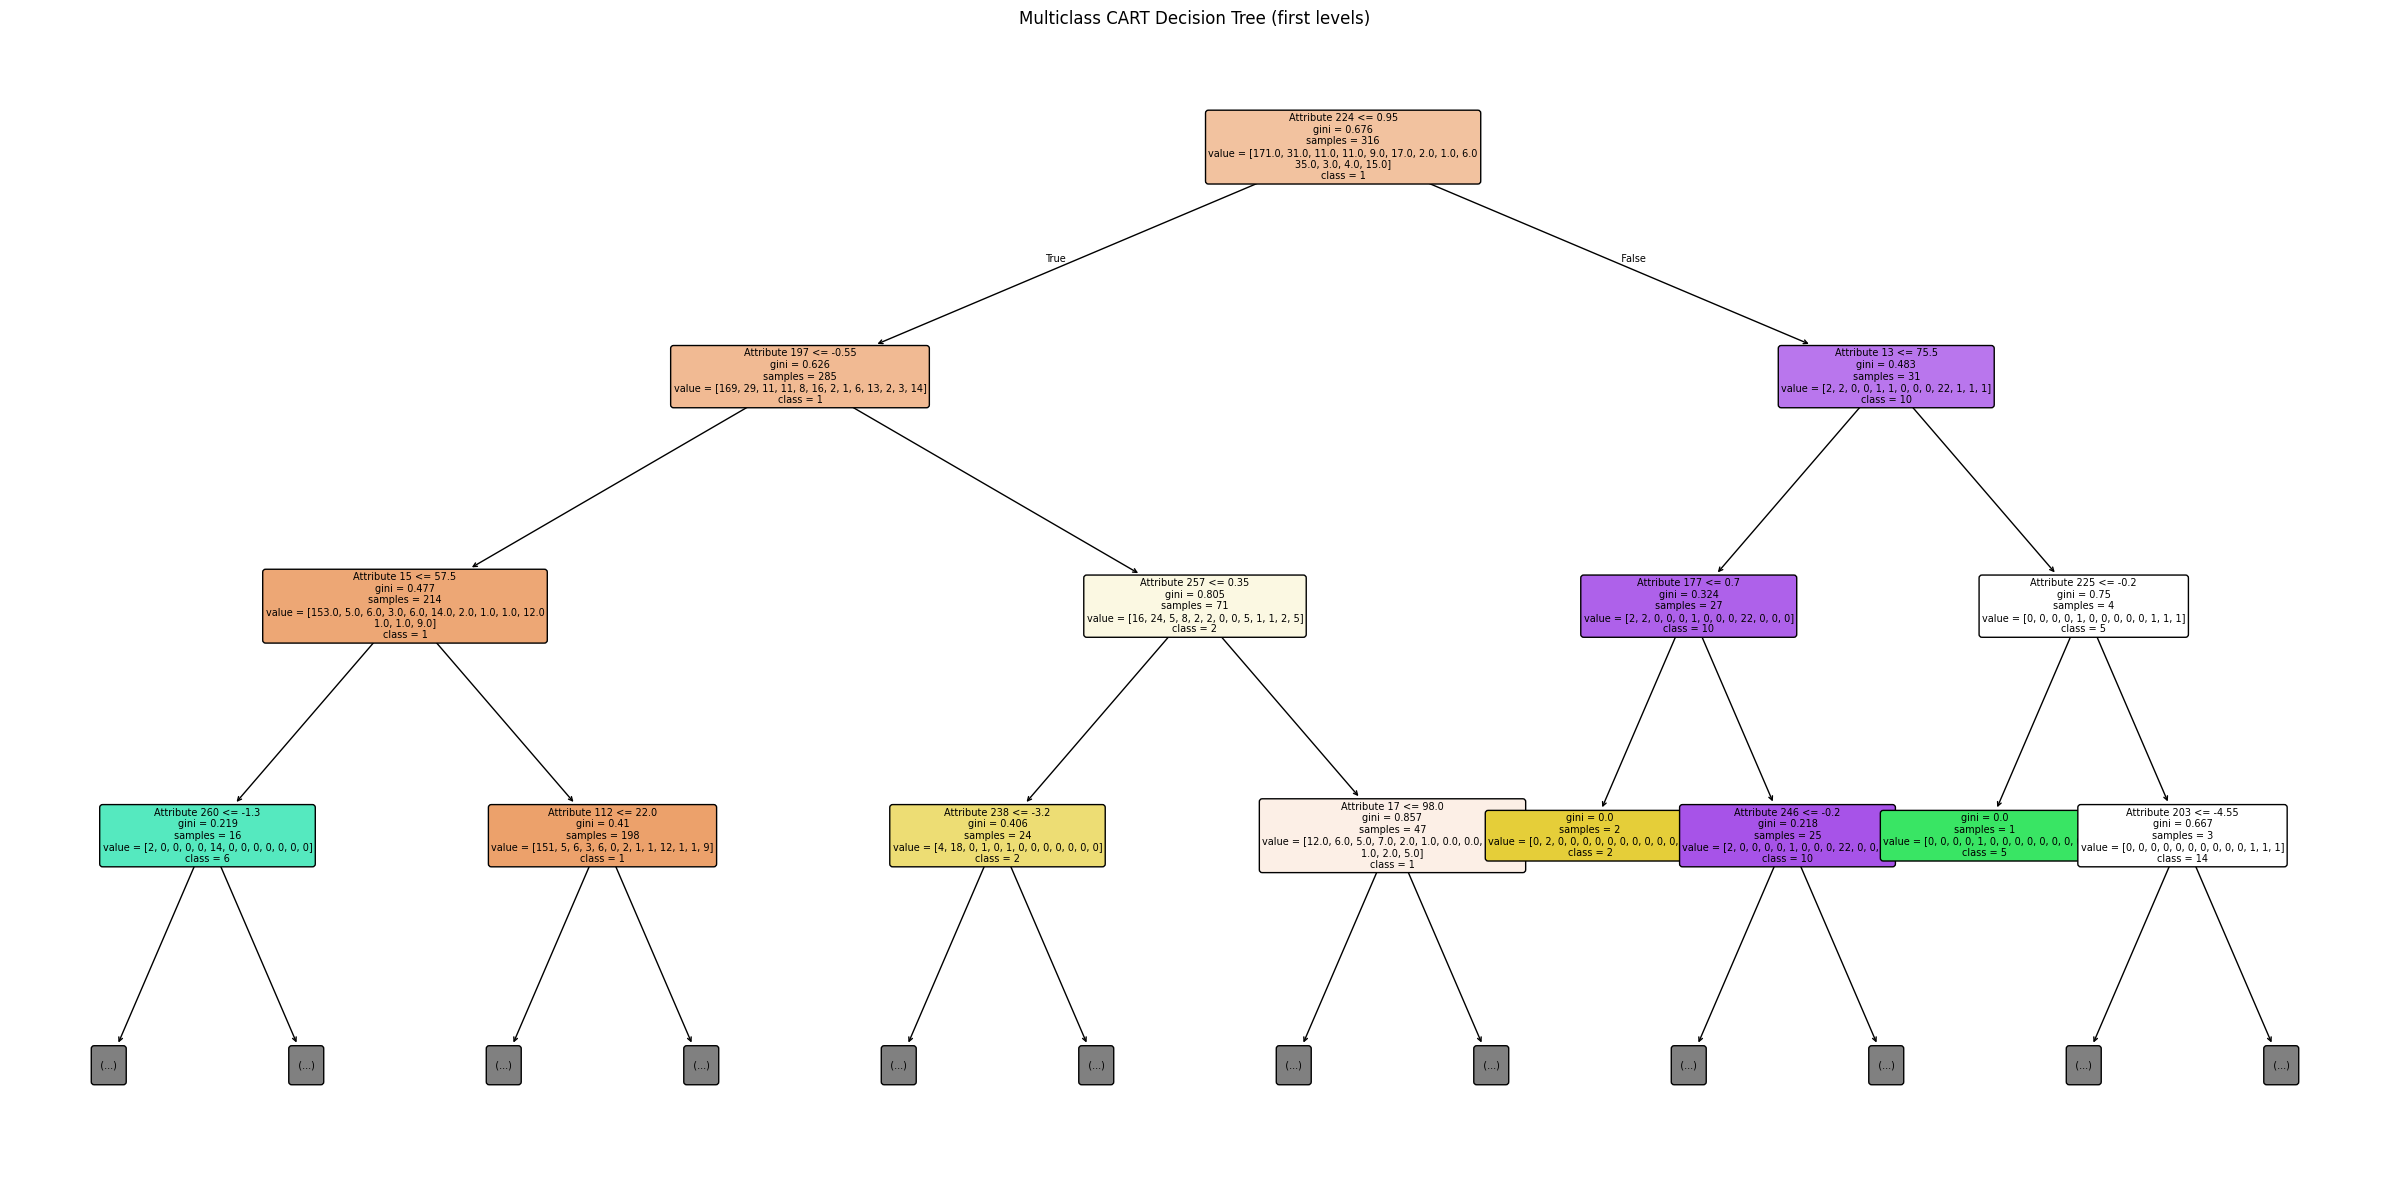

In [17]:
multi_tree = baseline_multiclass_model.named_steps["cart"]
feature_names = [f"Attribute {i+1}" if i < 13 else f"Attribute {i+2}" for i in range(X.shape[1])]

plt.figure(figsize=(24, 12))
plot_tree(
    multi_tree,
    max_depth=3,
    feature_names=feature_names,
    class_names=[str(label) for label in multi_tree.classes_],
    filled=True,
    rounded=True,
    fontsize=7
)
plt.title("Multiclass CART Decision Tree (first levels)")
plt.tight_layout()
plt.show()

,importance
Attribute 224,0.095134
Attribute 197,0.089635
Attribute 15,0.081805
Attribute 228,0.049933
Attribute 112,0.044514
Attribute 257,0.033127
Attribute 181,0.029795
Attribute 172,0.026677
Attribute 100,0.024603
Attribute 17,0.024347


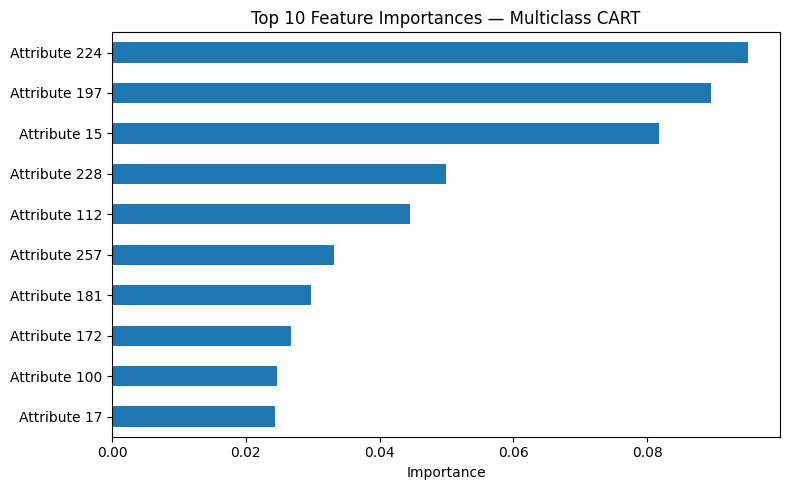

In [15]:
multi_importances = pd.Series(multi_tree.feature_importances_, index=feature_names)
top_multi_features = multi_importances.sort_values(ascending=False).head(10)
display(top_multi_features.rename("importance").to_frame())
top_multi_features.sort_values().plot(kind="barh", figsize=(8, 5))
plt.title("Top 10 Feature Importances — Multiclass CART")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

## 7. Demo

In [24]:
DEMO_ROW = 222
if not 0 <= DEMO_ROW < len(X):
    raise ValueError("DEMO_ROW must be between 0 and 451.")

record = X.loc[[DEMO_ROW]]
actual_class = int(y_multiclass.loc[DEMO_ROW])
baseline_prediction = int(baseline_multiclass_model.predict(record)[0])
tuned_prediction = int(tuned_multiclass_model.predict(record)[0])

print(f"Dataset row index: {DEMO_ROW}")
print(f"Actual original dataset class: {actual_class}")
print(f"Baseline multiclass CART prediction: {baseline_prediction}")
print(f"Tuned multiclass CART prediction: {tuned_prediction}")
print("\nFirst 12 input attributes for this record:")
display(record.iloc[:, :12])


Dataset row index: 222
Actual original dataset class: 6
Baseline multiclass CART prediction: 6
Tuned multiclass CART prediction: 6

First 12 input attributes for this record:


,0,1,2,3,4,5,6,7,8,9,10,11
222,56,0,173,84,98,173,372,161,86,72,38.0,50.0
